  # 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.13.0+cpu
Device : cpu


1. Jeu de données MNIST

MNIST contient 60 000 images d'entraînement et 10 000 images de test de chiffres manuscrits. Chaque image est en niveaux de gris et mesure 28 x 28 pixels.

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.35MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 268kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.03MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.54MB/s]

Train : 60000
Test  : 10000


Batch d'images : torch.Size([128, 1, 28, 28])
Batch de labels : torch.Size([128])
Valeurs des pixels : 0.0 -> 1.0


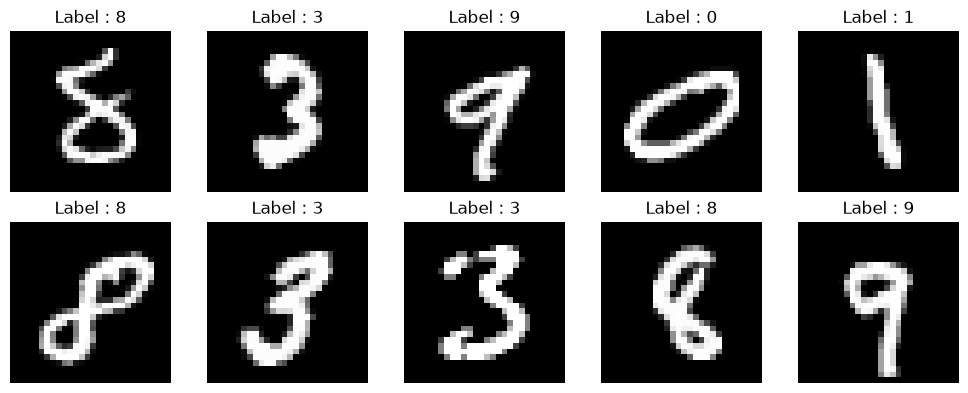

In [3]:
images, labels = next(iter(train_loader))
print("Batch d'images :", images.shape)
print("Batch de labels :", labels.shape)
print("Valeurs des pixels :", float(images.min()), "->", float(images.max()))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for image, label, ax in zip(images[:10], labels[:10], axes.flat):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Label : {label.item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cette cellule servira pour la Partie I : classification.

# Partie I - Modele discriminatif

## 2. Classification : apprendre P(y|x)

Le classifieur recoit une image `x` et predit le chiffre `y`. Il apprend a distinguer les classes 0 a 9, mais il ne genere pas de nouvelles images.

### Etape 1 - Construire le classifieur

`Flatten` transforme chaque image `[1, 28, 28]` en un vecteur de `784` pixels. Les couches `Linear` apprennent ensuite des caracteristiques et produisent 10 scores, un par chiffre.

In [ ]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
print(classifier)

### Verification des formes

Cette verification confirme que le modele transforme un lot `[B, 1, 28, 28]` en 10 scores `[B, 10]`.

In [ ]:
with torch.no_grad():
    sample_logits = classifier(images[:4].to(device))

print("Entree :", images[:4].shape)
print("Sortie :", sample_logits.shape)
print("Classe predite pour le premier exemple :", sample_logits[0].argmax().item())

### Etape 2 - Definir la fonction de perte et l'optimiseur

`CrossEntropyLoss` compare les 10 scores du modele au label correct. `Adam` modifie les poids du reseau pour reduire cette erreur.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

### Etape 3 - Entrainement

A chaque lot, le modele predit, calcule l'erreur, puis `backward()` calcule les gradients. `optimizer.step()` applique la mise a jour des poids.

In [ ]:
def train_classifier(model, loader, criterion, optimizer, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        mean_loss = total_loss / len(loader)
        print(f"Epoch {epoch + 1}/{epochs} - Loss = {mean_loss:.4f}")


train_classifier(classifier, train_loader, criterion, optimizer, epochs=3)

### Etape 4 - Evaluer le modele

On desactive l'apprentissage avec `eval()` et on ne calcule pas de gradients. L'accuracy mesure la proportion d'images correctement classees.

In [ ]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        predictions = model(x).argmax(dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    return correct / total


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy sur le jeu de test = {100 * accuracy:.2f}%")

### Conclusion

Le reseau apprend la relation `x -> y` : il reconnait le chiffre present dans une image. C'est un modele **discriminatif**, car il separe les classes. Il ne sait pas produire une nouvelle image de chiffre ; cette generation sera abordee avec les modeles generatifs.